In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv("uber.csv")
print("First five rows:")
display(df.head())
print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns)

First five rows:


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5



Dataset shape: (200000, 9)

Column names:
Index(['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'passenger_count'],
      dtype='object')


In [4]:
print("Dataset Information:")
df.info()
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())
print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB

Missing Values:
Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

Duplicate Rows: 0

Statistica

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [5]:
# Remove unnecessary column
#The key column is removed because it does not help predict the fare
df = df.drop(columns = ["Unnamed: 0","key"],errors ="ignore")

#Remove duplicate rows
df = df.drop_duplicates()

#Remove rows with missing values
df = df.dropna()

#Convert date time column
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"],errors = "coerce", utc= True)

df = df.dropna(subset =["pickup_datetime"])

df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["day_of_week"] = df["pickup_datetime"].dt.dayofweek

#Remove original date time column
df = df.drop(columns = ["pickup_datetime"])

#Keep valid fare amounts and passenger count
df = df[
    (df["fare_amount"] > 0) &
    (df["passenger_count"] >= 1)&
    (df["passenger_count"] <= 6)
    ]

#Validate geographic coordinates
df = df[
    df["pickup_longitude"].between(-180, 180) &
    df["dropoff_longitude"].between(-180, 180) &
    df["pickup_latitude"].between(-90,90) &
    df["dropoff_latitude"].between(-90,90)
    ]

print("Shape after preprocessing: ", df.shape)
display(df.head())

Shape after preprocessing:  (199256, 10)


,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,day_of_week
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,3
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,4
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,0
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,4
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,3


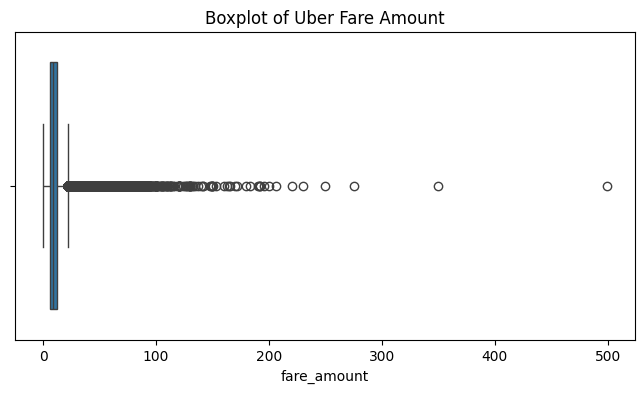

Lower Bound: -3.75
Upper Bound: 22.25
Number of outliers: 17120


In [6]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["fare_amount"])
plt.title("Boxplot of Uber Fare Amount")
plt.show()
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[
 (df["fare_amount"] < lower_bound) |
 (df["fare_amount"] > upper_bound)
]
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of outliers:", len(outliers))

Shape after removing fare outliers: (182136, 10)


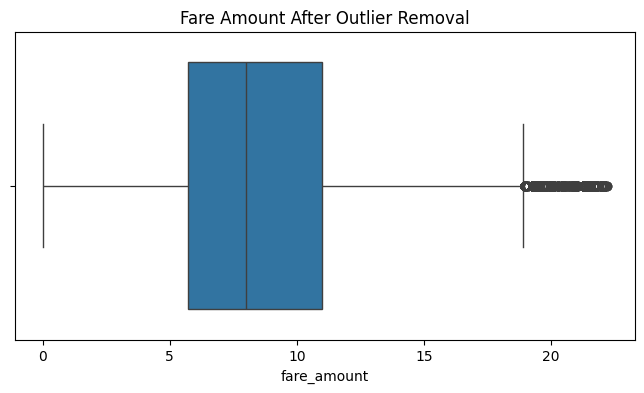

In [7]:
df = df[
 (df["fare_amount"] >= lower_bound) &
 (df["fare_amount"] <= upper_bound)
].copy()
print("Shape after removing fare outliers:", df.shape)
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["fare_amount"])
plt.title("Fare Amount After Outlier Removal")
plt.show()

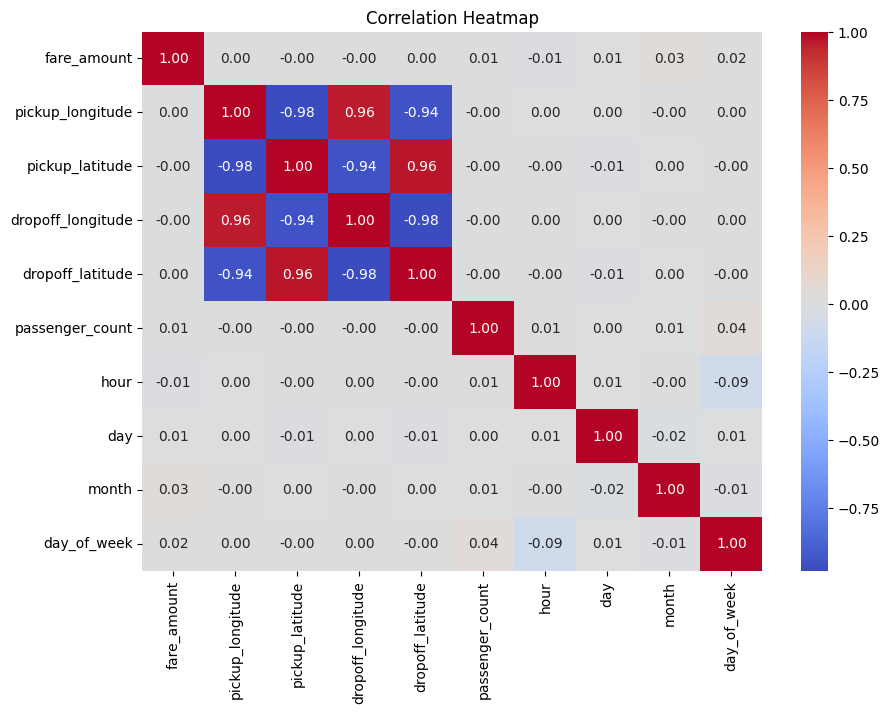

Correlation with fare_amount:
fare_amount          1.000000
month                0.026175
day_of_week          0.019886
passenger_count      0.012223
day                  0.007140
dropoff_latitude     0.000544
pickup_longitude     0.000134
pickup_latitude     -0.000590
dropoff_longitude   -0.000963
hour                -0.013293
Name: fare_amount, dtype: float64


In [8]:
correlation = df.corr(numeric_only=True)
plt.figure(figsize=(10, 7))
sns.heatmap(
 correlation,
 annot=True,
 cmap="coolwarm",
 fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()
print("Correlation with fare_amount:")
print(correlation["fare_amount"].sort_values(ascending=False))

In [9]:
#Feature selection:
X = df[
 [
 "pickup_longitude",
 "pickup_latitude",
 "dropoff_longitude",
 "dropoff_latitude",
 "passenger_count",
 "hour",
 "day",
 "month",
 "day_of_week"
 ]
]
y = df["fare_amount"]
X_train, X_test, y_train, y_test = train_test_split(
 X, y,
 test_size=0.2,
 random_state=42
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (145708, 9)
Testing data: (36428, 9)


In [10]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_test)
print("Linear Regression Model Trained Successfully")

Linear Regression Model Trained Successfully


In [11]:
rf_model = RandomForestRegressor(
 n_estimators=100,
 random_state=42,
 n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)
print("Random Forest Regression Model Trained Successfully")

Random Forest Regression Model Trained Successfully


In [12]:
#Model Evaluation
def evaluate_model(y_true, y_pred):
 mae = mean_absolute_error(y_true, y_pred)
 mse = mean_squared_error(y_true, y_pred)
 rmse = np.sqrt(mse)
 r2 = r2_score(y_true, y_pred)
 return mae, mse, rmse, r2
lr_mae, lr_mse, lr_rmse, lr_r2 = evaluate_model(
 y_test, lr_predictions
)
rf_mae, rf_mse, rf_rmse, rf_r2 = evaluate_model(
 y_test, rf_predictions
)
results = pd.DataFrame({
 "Model": ["Linear Regression", "Random Forest Regression"],
 "MAE": [lr_mae, rf_mae],
 "MSE": [lr_mse, rf_mse],
 "RMSE": [lr_rmse, rf_rmse],
 "R2 Score": [lr_r2, rf_r2]
})
display(results.round(4))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,3.2704,16.9971,4.1228,0.0011
1,Random Forest Regression,1.5256,4.7462,2.1786,0.7211


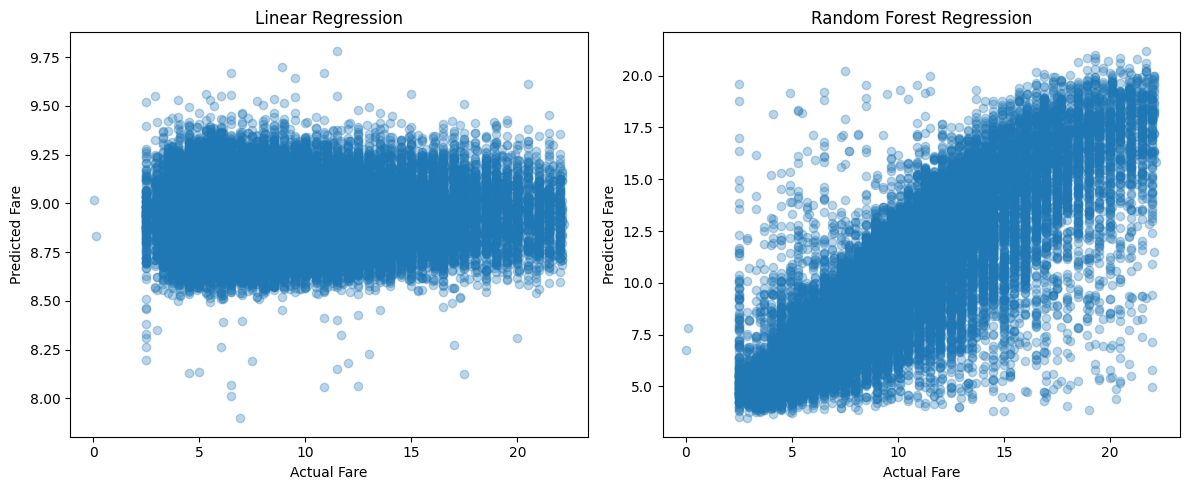

In [13]:
#Actual vs predicted fare
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(y_test, lr_predictions, alpha=0.3)
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Linear Regression")
plt.subplot(1, 2, 2)
plt.scatter(y_test, rf_predictions, alpha=0.3)
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Random Forest Regression")
plt.tight_layout()
plt.show()

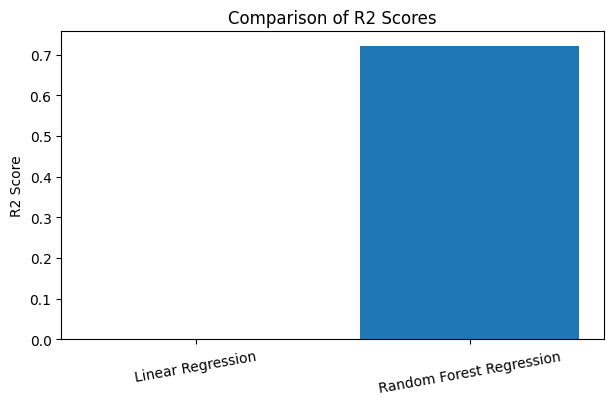

In [14]:
plt.figure(figsize=(7, 4))
plt.bar(results["Model"], results["R2 Score"])
plt.ylabel("R2 Score")
plt.title("Comparison of R2 Scores")
plt.xticks(rotation=10)
plt.show()

In [15]:
best_model_name = results.loc[
 results["R2 Score"].idxmax(), "Model"
]
print("Best Model based on R2 Score:", best_model_name)
print("\nModel Comparison:")
display(results.round(4))

Best Model based on R2 Score: Random Forest Regression

Model Comparison:


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,3.2704,16.9971,4.1228,0.0011
1,Random Forest Regression,1.5256,4.7462,2.1786,0.7211


In [16]:
#Sample Fare prediction:
sample_ride = pd.DataFrame([{
    "pickup_longitude" : -73.985,
    "pickup_latitude" : 40.758,
    "dropoff_longitude" : -73.985,
    "dropoff_latitude" : 40.748,
    "passenger_count" : 1,
    "hour" : 14,
    "day": 15,
    "month" : 6,
    "day_of_week":0
}])

lr_fare = lr_model.predict(sample_ride)[0]
rf_fare = rf_model.predict(sample_ride)[0]

print("Linear Regression Predicted Fare: ", round(lr_fare, 2))
print("Random Forest Predicted Fare: ", round(rf_fare,2))

Linear Regression Predicted Fare:  8.79
Random Forest Predicted Fare:  6.36
